In [1]:
'''
Perform chi-square tests of independence to explore and interpret relationships between categorical variables, 
evaluating statistical significance and guiding feature selection decisions.
'''
# import required libraries for data handling and statistics
# import pandas for tabular data and contingency tables
import pandas as pd

# import numpy for numerical computations
import numpy as np

# import scipy stats for chi-square test of independence
import scipy.stats as stats
from scipy.stats import chi2_contingency

# import matplotlib for simple plots
import matplotlib.pyplot as plt


In [2]:
# load sample records from the pharmacy dataset
df = pd.read_csv('global_pharmacy_sales_2020_2025_daily_dataset.csv', nrows=10000)

# create categorical demand level and price tier variables
df['price_tier'] = pd.qcut(df['unit_price'], q=3, labels=['Budget', 'Moderate', 'Premium'])
df['demand_level'] = pd.qcut(df['units_sold'], q=2, labels=['Low_Demand', 'High_Demand'])
df['pandemic_period'] = df['covid_flag'].map({0: 'Non_Covid', 1: 'Covid'})

print("Dataset loaded successfully.")
print(f"Total rows analyzed: {len(df)}")
print("Sample categorical data:")
print(df[['category', 'age_group', 'region', 'price_tier', 'pandemic_period', 'demand_level']].head())


Dataset loaded successfully.
Total rows analyzed: 10000
Sample categorical data:
  category age_group         region price_tier pandemic_period demand_level
0  Chronic      0-12    Middle East   Moderate       Non_Covid   Low_Demand
1  Chronic     26-45     South Asia    Premium           Covid   Low_Demand
2  Vitamin      0-12    Middle East     Budget           Covid  High_Demand
3  Chronic      0-12     South Asia   Moderate       Non_Covid   Low_Demand
4  Chronic     26-45  South America   Moderate       Non_Covid  High_Demand


In [3]:
# create contingency table of observed counts between pandemic period and demand level
observed = pd.crosstab(df['pandemic_period'], df['demand_level'])
print("Observed Frequencies Table:")
print(observed)

# run chi-square test to get expected frequencies and statistics
chi2_val, p_val, dof, expected = chi2_contingency(observed)

# convert expected frequencies to a clean dataframe
expected_df = pd.DataFrame(expected, index=observed.index, columns=observed.columns).round(2)
print("\nExpected Frequencies Table (under null hypothesis of independence):")
print(expected_df)


Observed Frequencies Table:
demand_level     Low_Demand  High_Demand
pandemic_period                         
Covid                   688         2545
Non_Covid              4345         2422

Expected Frequencies Table (under null hypothesis of independence):
demand_level     Low_Demand  High_Demand
pandemic_period                         
Covid               1627.17      1605.83
Non_Covid           3405.83      3361.17


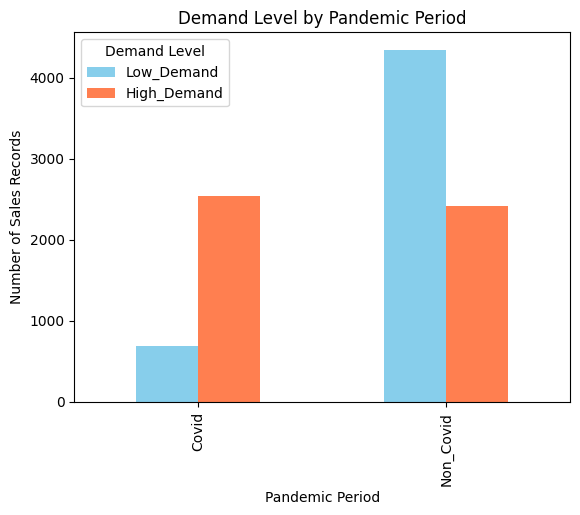

In [4]:
# simple bar chart comparing observed counts using matplotlib
observed.plot(kind='bar', color=['skyblue', 'coral'])
plt.title("Demand Level by Pandemic Period")
plt.xlabel("Pandemic Period")
plt.ylabel("Number of Sales Records")
plt.legend(title="Demand Level")
plt.show()


In [5]:
# calculate cramers v to measure strength of association
n_total = observed.sum().sum()
min_dim = min(observed.shape) - 1
cramers_v = np.sqrt(chi2_val / (n_total * min_dim))

# critical chi-square value at alpha = 0.05
alpha = 0.05
critical_chi2 = stats.chi2.ppf(1 - alpha, dof)

print("Chi-Square Test Results:")
print(f"Chi-square statistic: {chi2_val:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"Critical value cutoff: {critical_chi2:.4f}")
print(f"Calculated p-value: {p_val:.4e}")
print(f"Cramer's V effect size: {cramers_v:.4f}\n")

if p_val < alpha and chi2_val > critical_chi2:
    print("Conclusion: Because the p-value is less than 0.05, we reject the null hypothesis.")
    print("There is a statistically significant relationship between pandemic period and demand level.")
else:
    print("Conclusion: Fail to reject the null hypothesis. The variables are independent.")


Chi-Square Test Results:
Chi-square statistic: 1611.0235
Degrees of freedom: 1
Critical value cutoff: 3.8415
Calculated p-value: 0.0000e+00
Cramer's V effect size: 0.4014

Conclusion: Because the p-value is less than 0.05, we reject the null hypothesis.
There is a statistically significant relationship between pandemic period and demand level.


In [6]:
# test multiple candidate categorical features against the target variable
target_var = 'demand_level'
candidate_features = ['category', 'age_group', 'region', 'price_tier', 'pandemic_period']

feature_results = []

for feature in candidate_features:
    # compute contingency table
    contingency = pd.crosstab(df[feature], df[target_var])
    
    # compute chi-square test
    chi2, p, df_val, _ = chi2_contingency(contingency)
    
    # compute cramers v effect size
    total_n = contingency.sum().sum()
    dim_min = min(contingency.shape) - 1
    v_score = np.sqrt(chi2 / (total_n * dim_min))
    
    # feature selection decision rule
    if p < 0.05:
        decision = "Selected"
    else:
        decision = "Dropped"
        
    feature_results.append({
        'Feature': feature,
        'Chi2_Statistic': round(chi2, 2),
        'p_value': p,
        'Degrees_of_Freedom': df_val,
        'Cramers_V': round(v_score, 4),
        'Selection_Decision': decision
    })

# create summary table
selection_summary = pd.DataFrame(feature_results).sort_values(by='Chi2_Statistic', ascending=False)
print("Feature Selection Summary Table:")
print(selection_summary.to_string(index=False))


Feature Selection Summary Table:
        Feature  Chi2_Statistic  p_value  Degrees_of_Freedom  Cramers_V Selection_Decision
pandemic_period         1611.02 0.000000                   1     0.4014           Selected
       category            6.09 0.192228                   4     0.0247            Dropped
     price_tier            5.82 0.054412                   2     0.0241            Dropped
         region            4.38 0.735407                   7     0.0209            Dropped
      age_group            1.05 0.902670                   4     0.0102            Dropped


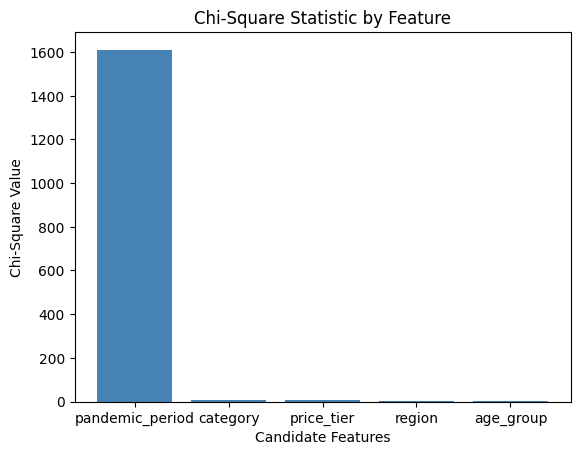

In [7]:
# simple bar chart showing chi-square statistics for candidate features
plt.bar(selection_summary['Feature'], selection_summary['Chi2_Statistic'], color='steelblue')
plt.title("Chi-Square Statistic by Feature")
plt.xlabel("Candidate Features")
plt.ylabel("Chi-Square Value")
plt.show()


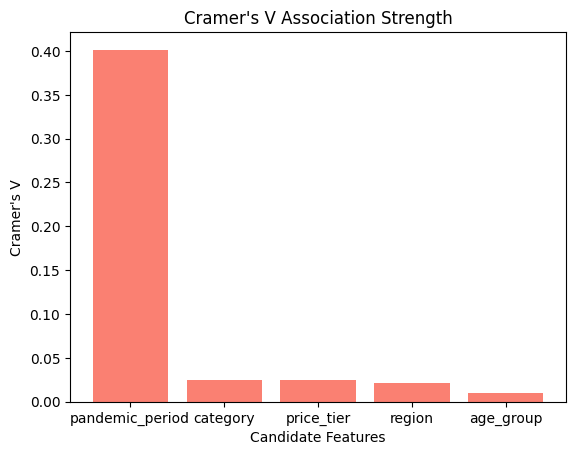

In [8]:
# simple bar chart showing association strength (cramer's v)
plt.bar(selection_summary['Feature'], selection_summary['Cramers_V'], color='salmon')
plt.title("Cramer's V Association Strength")
plt.xlabel("Candidate Features")
plt.ylabel("Cramer's V")
plt.show()


In [9]:
# display final feature selection conclusion
selected_features = selection_summary[selection_summary['Selection_Decision'] == 'Selected']['Feature'].tolist()
dropped_features = selection_summary[selection_summary['Selection_Decision'] == 'Dropped']['Feature'].tolist()

print("Final Feature Selection Decisions:")
print(f"Selected features for model training: {', '.join(selected_features)}")
print(f"Dropped features due to independence: {', '.join(dropped_features)}\n")

print("Practical Takeaway:")
print("Features with p < 0.05 show a meaningful relationship with the target and improve prediction.")
print("Features with p >= 0.05 are independent of the target and dropping them prevents overfitting.")


Final Feature Selection Decisions:
Selected features for model training: pandemic_period
Dropped features due to independence: category, price_tier, region, age_group

Practical Takeaway:
Features with p < 0.05 show a meaningful relationship with the target and improve prediction.
Features with p >= 0.05 are independent of the target and dropping them prevents overfitting.
